In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

Y = np.array([
    [0],
    [1],
    [1],
    [0]
])

In [3]:
print("Input shape:", X.shape)
print("Target shape:", Y.shape)

print("\nInputs:\n", X)
print("\nTargets:\n", Y)

Input shape: (4, 2)
Target shape: (4, 1)

Inputs:
 [[0 0]
 [0 1]
 [1 0]
 [1 1]]

Targets:
 [[0]
 [1]
 [1]
 [0]]


In [4]:
np.random.seed(42)

W1 = np.random.randn(2, 2) * 0.01
b1 = np.zeros((1, 2))

W2 = np.random.randn(2, 1) * 0.01
b2 = np.zeros((1, 1))

In [5]:
print("W1:\n", W1)
print("\nb1:\n", b1)

print("\nW2:\n", W2)
print("\nb2:\n", b2)

W1:
 [[ 0.00496714 -0.00138264]
 [ 0.00647689  0.0152303 ]]

b1:
 [[0. 0.]]

W2:
 [[-0.00234153]
 [-0.00234137]]

b2:
 [[0.]]


In [6]:
print("W1 shape:", W1.shape)
print("b1 shape:", b1.shape)

print("W2 shape:", W2.shape)
print("b2 shape:", b2.shape)

W1 shape: (2, 2)
b1 shape: (1, 2)
W2 shape: (2, 1)
b2 shape: (1, 1)


In [7]:
Z1 = np.dot(X, W1) + b1
A1 = np.maximum(0, Z1)

print("Z1:\n", Z1)
print("\nA1:\n", A1)

print("\nZ1 shape:", Z1.shape)
print("A1 shape:", A1.shape)

Z1:
 [[ 0.          0.        ]
 [ 0.00647689  0.0152303 ]
 [ 0.00496714 -0.00138264]
 [ 0.01144403  0.01384766]]

A1:
 [[0.         0.        ]
 [0.00647689 0.0152303 ]
 [0.00496714 0.        ]
 [0.01144403 0.01384766]]

Z1 shape: (4, 2)
A1 shape: (4, 2)


In [8]:
Z2 = np.dot(A1, W2) + b2
A2 = 1 / (1 + np.exp(-Z2))

print("Z2:\n", Z2)
print("\nPredictions:\n", A2)

print("\nZ2 shape:", Z2.shape)
print("A2 shape:", A2.shape)

Z2:
 [[ 0.00000000e+00]
 [-5.08256033e-05]
 [-1.16307295e-05]
 [-5.92190545e-05]]

Predictions:
 [[0.5       ]
 [0.49998729]
 [0.49999709]
 [0.4999852 ]]

Z2 shape: (4, 1)
A2 shape: (4, 1)


In [9]:
print("Actual targets:")
print(Y)

print("\nInitial predictions:")
print(A2)

Actual targets:
[[0]
 [1]
 [1]
 [0]]

Initial predictions:
[[0.5       ]
 [0.49998729]
 [0.49999709]
 [0.4999852 ]]


In [10]:
epsilon = 1e-8

loss = -np.mean(
    Y * np.log(A2 + epsilon) +
    (1 - Y) * np.log(1 - A2 + epsilon)
)

print("Binary cross-entropy loss:", loss)

Binary cross-entropy loss: 0.6931475654142657


In [11]:
m = X.shape[0]

dZ2 = A2 - Y

dW2 = np.dot(A1.T, dZ2) / m
db2 = np.sum(dZ2, axis=0, keepdims=True) / m

print("dZ2:\n", dZ2)
print("\ndW2:\n", dW2)
print("\ndb2:\n", db2)

print("\nGradient shapes:")
print("dZ2:", dZ2.shape)
print("dW2:", dW2.shape)
print("db2:", db2.shape)

dZ2:
 [[ 0.5       ]
 [-0.50001271]
 [-0.50000291]
 [ 0.4999852 ]]

dW2:
 [[-6.65417213e-08]
 [-1.72930010e-04]]

db2:
 [[-7.60471171e-06]]

Gradient shapes:
dZ2: (4, 1)
dW2: (2, 1)
db2: (1, 1)


# Initialize Inputs

In [12]:
# Defining inputs and expected output (XOR truth table)
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # 2x4 matrix, each column is a training example
d = np.array([0, 1, 1, 0])  # Expected output for XOR

# Declare the network parameters & the weights

In [13]:
def initialize_network_parameters():
    # Network parameters
    inputSize = 2      # Number of input neurons (x1, x2)
    hiddenSize = 2     # Number of hidden neurons
    outputSize = 1     # Number of output neurons
    lr = 0.1           # Learning rate
    epochs = 180000    # Number of training epochs

    # Initialize weights and biases randomly within the range [-1, 1]
    w1 = np.random.rand(hiddenSize, inputSize) * 2 - 1  # Weights from input to hidden layer
    b1 = np.random.rand(hiddenSize, 1) * 2 - 1          # Bias for hidden layer
    w2 = np.random.rand(outputSize, hiddenSize) * 2 - 1 # Weights from hidden to output layer
    b2 = np.random.rand(outputSize, 1) * 2 - 1          # Bias for output layer

    return w1, b1, w2, b2, lr, epochs


# Training the Neural Network

In [14]:
# Get initialized parameters
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()

# Training the network using backpropagation
error_list = []
for epoch in range(epochs):
    # Forward pass
    z1 = np.dot(w1, X) + b1  # Weighted sum for hidden layer
    a1 = 1 / (1 + np.exp(-z1))  # Sigmoid activation for hidden layer

    z2 = np.dot(w2, a1) + b2  # Weighted sum for output layer
    a2 = 1 / (1 + np.exp(-z2))  # Sigmoid activation for output layer

    # Error calculation and backpropagation
    error = d - a2  # Difference between expected and actual output
    da2 = error * (a2 * (1 - a2))  # Derivative for output layer
    dz2 = da2  # Gradient for output layer

    # Propagate error to hidden layer
    da1 = np.dot(w2.T, dz2)  # Gradient for hidden layer
    dz1 = da1 * (a1 * (1 - a1))  # Derivative for hidden layer

    # Update weights and biases
    w2 += lr * np.dot(dz2, a1.T)  # Update weights from hidden to output layer
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)  # Update bias for output layer

    w1 += lr * np.dot(dz1, X.T)  # Update weights from input to hidden layer
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)  # Update bias for hidden layer
    if (epoch+1)%10000 == 0:
        print("Epoch: %d, Average error: %0.05f"%(epoch, np.average(abs(error))))
        error_list.append(np.average(abs(error)))

Epoch: 9999, Average error: 0.04654
Epoch: 19999, Average error: 0.02874
Epoch: 29999, Average error: 0.02241
Epoch: 39999, Average error: 0.01894
Epoch: 49999, Average error: 0.01668
Epoch: 59999, Average error: 0.01507
Epoch: 69999, Average error: 0.01384
Epoch: 79999, Average error: 0.01286
Epoch: 89999, Average error: 0.01207
Epoch: 99999, Average error: 0.01140
Epoch: 109999, Average error: 0.01083
Epoch: 119999, Average error: 0.01034
Epoch: 129999, Average error: 0.00991
Epoch: 139999, Average error: 0.00953
Epoch: 149999, Average error: 0.00918
Epoch: 159999, Average error: 0.00888
Epoch: 169999, Average error: 0.00860
Epoch: 179999, Average error: 0.00834


In [15]:
# Testing the trained network
z1 = np.dot(w1, X) + b1  # Weighted sum for hidden layer
a1 = 1 / (1 + np.exp(-z1))  # Sigmoid activation for hidden layer

z2 = np.dot(w2, a1) + b2  # Weighted sum for output layer
a2 = 1 / (1 + np.exp(-z2))  # Sigmoid activation for output layer

# Print results
print('Final output after training:', a2)
print('Ground truth', d)
print('Error after training:', error)
print('Average error: %0.05f'%np.average(abs(error)))

Final output after training: [[0.0083765  0.99210584 0.99040363 0.00749766]]
Ground truth [0 1 1 0]
Error after training: [[-0.00837652  0.00789418  0.0095964  -0.00749768]]
Average error: 0.00834


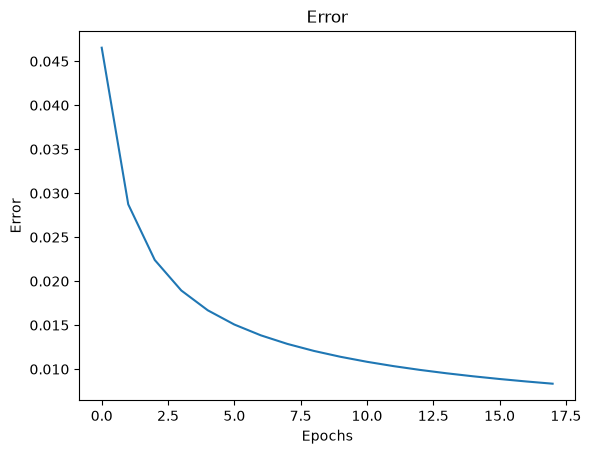

In [16]:
# Plot error
plt.plot(error_list)
plt.title('Error')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()

Epoch: 9999, Average error: 0.02552
Epoch: 19999, Average error: 0.01622
Epoch: 29999, Average error: 0.01267
Epoch: 39999, Average error: 0.01069
Epoch: 49999, Average error: 0.00940
Epoch: 59999, Average error: 0.00847
Epoch: 69999, Average error: 0.00776
Epoch: 79999, Average error: 0.00720
Epoch: 89999, Average error: 0.00674
Epoch: 99999, Average error: 0.00636
Epoch: 109999, Average error: 0.00603
Epoch: 119999, Average error: 0.00575
Epoch: 129999, Average error: 0.00550
Epoch: 139999, Average error: 0.00528
Epoch: 149999, Average error: 0.00509
Epoch: 159999, Average error: 0.00491
Epoch: 169999, Average error: 0.00475
Epoch: 179999, Average error: 0.00461

Final output after training: [[1.81691309e-04 4.79949872e-03 4.76370713e-03 9.91319006e-01]]
Ground truth [0 0 0 1]
Error after training: [[-0.00018169 -0.00479951 -0.00476372  0.00868102]]
Average error: 0.00461


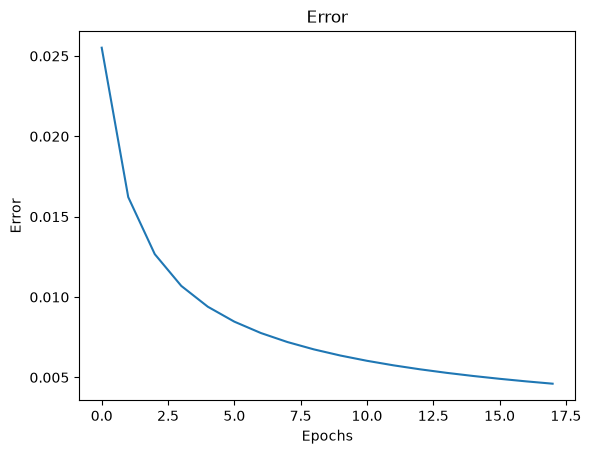

In [17]:
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]]).T  # 2x4 matrix, each column is a training example
d = np.array([0, 0, 0, 1])  # Expected output for AND

# Get initialized parameters
w1, b1, w2, b2, lr, epochs = initialize_network_parameters()

# Training the network using backpropagation
error_list = []
for epoch in range(epochs):
    # Forward pass
    z1 = np.dot(w1, X) + b1  # Weighted sum for hidden layer
    a1 = 1 / (1 + np.exp(-z1))  # Sigmoid activation for hidden layer

    z2 = np.dot(w2, a1) + b2  # Weighted sum for output layer
    a2 = 1 / (1 + np.exp(-z2))  # Sigmoid activation for output layer

    # Error calculation and backpropagation
    error = d - a2  # Difference between expected and actual output
    da2 = error * (a2 * (1 - a2))  # Derivative for output layer
    dz2 = da2  # Gradient for output layer

    # Propagate error to hidden layer
    da1 = np.dot(w2.T, dz2)  # Gradient for hidden layer
    dz1 = da1 * (a1 * (1 - a1))  # Derivative for hidden layer

    # Update weights and biases
    w2 += lr * np.dot(dz2, a1.T)  # Update weights from hidden to output layer
    b2 += lr * np.sum(dz2, axis=1, keepdims=True)  # Update bias for output layer

    w1 += lr * np.dot(dz1, X.T)  # Update weights from input to hidden layer
    b1 += lr * np.sum(dz1, axis=1, keepdims=True)  # Update bias for hidden layer
    if (epoch+1)%10000 == 0:
        print("Epoch: %d, Average error: %0.05f"%(epoch, np.average(abs(error))))
        error_list.append(np.average(abs(error)))


# Testing the trained network
z1 = np.dot(w1, X) + b1  # Weighted sum for hidden layer
a1 = 1 / (1 + np.exp(-z1))  # Sigmoid activation for hidden layer

z2 = np.dot(w2, a1) + b2  # Weighted sum for output layer
a2 = 1 / (1 + np.exp(-z2))  # Sigmoid activation for output layer

# Print results
print('\nFinal output after training:', a2)
print('Ground truth', d)
print('Error after training:', error)
print('Average error: %0.05f'%np.average(abs(error)))

# Plot error
plt.plot(error_list)
plt.title('Error')
plt.xlabel('Epochs')
plt.ylabel('Error')
plt.show()
